# Bab 10 — Neural Learning about Edges and Corners: Intro to CNNs

**Acuan:** Trask, *Grokking Deep Learning*, Bab 10, hlm. 177–185. Buku memakai MNIST 28×28; notebook ini menggunakan **`load_digits` 8×8 bawaan scikit-learn** agar bisa dieksekusi offline. Implementasi patch extraction, konvolusi, backprop, dan klasifikasi ditulis mandiri.

**Tujuan belajar:** memahami weight sharing, receptive field, feature map, dimensi output, dan bagaimana gradien satu kernel menggabungkan kontribusi dari semua posisi gambar.

## 1. Satu filter, banyak lokasi

Pada layer konvolusi, matriks kecil $K$ digunakan ulang di tiap jendela citra. Ini berbeda dari dense layer yang memberi bobot terpisah ke setiap pasangan piksel–neuron. Operasi yang diimplementasikan di bawah secara teknis adalah **cross-correlation** (kernel tidak dibalik), sesuai kebiasaan banyak pustaka deep learning yang menyebutnya convolution. Untuk citra $8\times8$ dan kernel $3\times3$, tanpa padding dan stride 1, peta fitur berukuran $(8-3+1)\times(8-3+1)=6\times6$.

Kernel contoh berikut sengaja tetap dan sederhana; ia mendeteksi perubahan intensitas horizontal, bukan kernel yang sudah dipelajari.

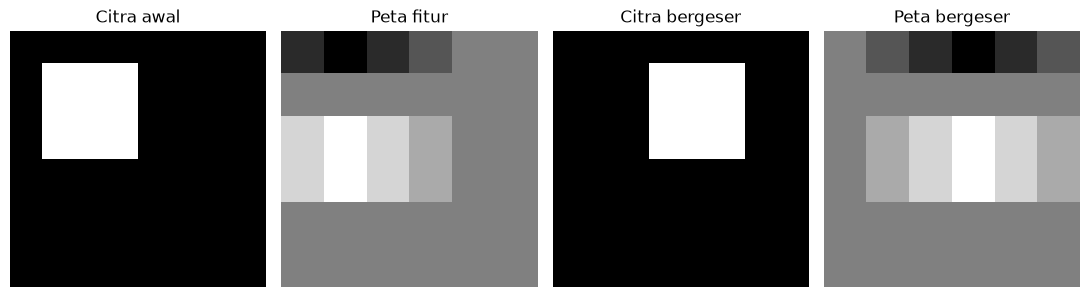

Ukuran input/output: (8, 8) (6, 6)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.datasets import load_digits

image = np.zeros((8, 8))
image[1:4, 1:4] = 1
shifted = np.zeros((8, 8))
shifted[1:4, 3:6] = 1
horizontal_edge = np.array([[1., 1., 1.], [0., 0., 0.], [-1., -1., -1.]])

def correlate_valid(img, kernel):
    patches = sliding_window_view(img, kernel.shape)
    return np.einsum('ijab,ab->ij', patches, kernel)

response = correlate_valid(image, horizontal_edge)
response_shifted = correlate_valid(shifted, horizontal_edge)
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, array, title in zip(axes, [image, response, shifted, response_shifted],
                             ['Citra awal', 'Peta fitur', 'Citra bergeser', 'Peta bergeser']):
    ax.imshow(array, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()
print('Ukuran input/output:', image.shape, response.shape)
assert response.shape == (6, 6)
assert np.allclose(response_shifted[:, 2:], response[:, :-2])

## 2. Weight sharing dan jumlah parameter

Untuk $K$ kernel $3\times3$ pada citra satu kanal, layer konvolusi punya $9K$ bobot (+ $K$ bias), tidak bergantung pada banyaknya lokasi. Dengan delapan kernel, output memiliki $6\times6\times8=288$ nilai, tetapi hanya $72$ bobot kernel. Dense layer yang memetakan 64 piksel langsung ke 288 unit memerlukan $64\times288=18.432$ bobot. Perbandingan ini menyangkut layer pertama saja; classifier sesudahnya tetap menambah parameter. Weight sharing memberi *inductive bias* bahwa fitur lokal yang berguna di satu lokasi juga berguna di lokasi lain; tidak selalu cocok untuk semua data.

In [2]:
kernel_size, n_kernels = 3, 8
conv_weights = kernel_size**2 * n_kernels
dense_weights = 64 * (6*6*n_kernels)
print('Bobot konvolusi:', conv_weights, 'vs dense pertama:', dense_weights)
print('Rasio:', dense_weights / conv_weights)
assert conv_weights == 72 and dense_weights == 18432

Bobot konvolusi: 72 vs dense pertama: 18432
Rasio: 256.0


## 3. Dataset dan forward pass CNN kecil

Kita memakai 800 citra untuk training, 400 untuk validation, sisanya test. Normalisasi dengan skala intensitas dataset yang diketahui (16) tidak belajar apa pun dari validation/test. `sliding_window_view` membuat 36 patch per gambar, lalu matriks kernel berukuran $9\times8$ dihitung pada semua patch. ReLU menghasilkan delapan feature map yang diratakan sebelum dense classifier dan softmax. Tidak ada pooling; tujuan notebook adalah memperjelas weight sharing dan gradien kernel.

In [3]:
digits = load_digits()
rng = np.random.default_rng(23)
order = rng.permutation(len(digits.images))
train_ids, val_ids, test_ids = order[:800], order[800:1200], order[1200:]
images = digits.images / 16.0
labels = digits.target
X_train, y_train = images[train_ids], labels[train_ids]
X_val, y_val = images[val_ids], labels[val_ids]
X_test, y_test = images[test_ids], labels[test_ids]

def patches_of(batch):
    windows = sliding_window_view(batch, (3, 3), axis=(1, 2))
    return windows.reshape(len(batch), 36, 9)

def softmax(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / exp_values.sum(axis=1, keepdims=True)

def initialize(seed=9):
    random = np.random.default_rng(seed)
    kernels = random.normal(0, .08, size=(9, 8))
    conv_bias = np.zeros((1, 1, 8))
    dense = random.normal(0, .04, size=(288, 10))
    output_bias = np.zeros((1, 10))
    return [kernels, conv_bias, dense, output_bias]

def forward(batch, params):
    kernels, conv_bias, dense, output_bias = params
    patches = patches_of(batch)
    pre = patches @ kernels + conv_bias
    feature_maps = np.maximum(0, pre)
    flattened = feature_maps.reshape(len(batch), -1)
    probs = softmax(flattened @ dense + output_bias)
    return patches, pre, flattened, probs

params = initialize()
patches, pre, flat, probs = forward(X_train[:5], params)
print('Batch/patches/maps/flatten/probabilities:', X_train[:5].shape, patches.shape,
      pre.shape, flat.shape, probs.shape)
assert patches.shape == (5, 36, 9) and probs.shape == (5, 10)

Batch/patches/maps/flatten/probabilities: (5, 8, 8) (5, 36, 9) (5, 36, 8) (5, 288) (5, 10)


## 4. Backpropagation untuk kernel yang dipakai berulang

Cross-entropy dengan softmax memberi $dZ=(P-Y)/m$. Gradien dense diperoleh dari aktivasi feature map yang diratakan. Untuk kernel, sinyal error dari semua lokasi patch dijumlahkan: $dK_{jk}=\sum_{i,p}\mathrm{patch}_{ipj}\,d\mathrm{pre}_{ipk}$. Inilah konsekuensi weight sharing dalam backward pass: satu bobot kernel menerima kontribusi dari setiap lokasi tempat ia dipakai. Mask ReLU memblokir gradien pada aktivasi negatif. Kita periksa satu elemen kernel dengan beda hingga.

In [4]:
def cross_entropy(prob, target):
    return float(-np.mean(np.log(np.clip(prob[np.arange(len(target)), target], 1e-12, 1))))

def gradients(batch, target, params):
    kernels, conv_bias, dense, output_bias = params
    patches, pre, flat, prob = forward(batch, params)
    dlogits = prob.copy()
    dlogits[np.arange(len(target)), target] -= 1
    dlogits /= len(target)
    gdense = flat.T @ dlogits
    goutput_bias = dlogits.sum(axis=0, keepdims=True)
    dfeatures = (dlogits @ dense.T).reshape(len(batch), 36, 8)
    dpre = dfeatures * (pre > 0)
    gkernels = np.einsum('npj,npk->jk', patches, dpre)
    gconv_bias = dpre.sum(axis=(0, 1), keepdims=True)
    return [gkernels, gconv_bias, gdense, goutput_bias]

small_x, small_y = X_train[:12], y_train[:12]
analytic = gradients(small_x, small_y, params)[0][0, 0]
epsilon = 1e-5
plus = [part.copy() for part in params]; minus = [part.copy() for part in params]
plus[0][0, 0] += epsilon; minus[0][0, 0] -= epsilon
numeric = (cross_entropy(forward(small_x, plus)[-1], small_y)
           - cross_entropy(forward(small_x, minus)[-1], small_y)) / (2*epsilon)
print('Gradien kernel[0,0], analitik/numerik:', round(analytic, 7), round(numeric, 7))
assert np.isclose(analytic, numeric, atol=1e-6)

Gradien kernel[0,0], analitik/numerik: -0.0007292 -0.0007292


## 5. Latih, pilih dengan validation, uji sekali

Mini-batch memperbarui bobot setelah beberapa citra. Kita menyimpan keadaan dengan validation loss terendah selama pelatihan, lalu memakai test set hanya untuk laporan akhir. Model kecil ini bertujuan menunjukkan alur CNN, bukan menyaingi arsitektur modern. Kernel dan feature map dapat dipelajari untuk mengenali garis/lekuk, tetapi menamai satu kernel sebagai 'pendeteksi sudut' memerlukan inspeksi dan bukti lebih dari satu visualisasi.

Validation epoch terbaik: 40 loss: 0.21
Test accuracy: 0.941 test images: 597


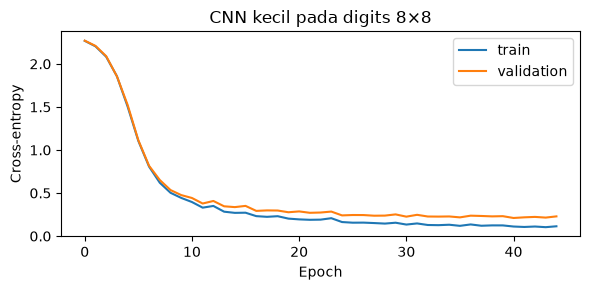

In [5]:
history = {'train': [], 'val': []}
best_params, best_epoch, best_val = None, None, float('inf')
learning_rate = .08
for epoch in range(45):
    for ids in np.array_split(rng.permutation(len(X_train)), 10):
        batch, target = X_train[ids], y_train[ids]
        grads = gradients(batch, target, params)
        params = [p - learning_rate*g for p, g in zip(params, grads)]
    train_loss = cross_entropy(forward(X_train, params)[-1], y_train)
    val_loss = cross_entropy(forward(X_val, params)[-1], y_val)
    history['train'].append(train_loss); history['val'].append(val_loss)
    if val_loss < best_val:
        best_val, best_epoch = val_loss, epoch
        best_params = [part.copy() for part in params]

test_probs = forward(X_test, best_params)[-1]
test_accuracy = np.mean(test_probs.argmax(axis=1) == y_test)
print('Validation epoch terbaik:', best_epoch, 'loss:', round(best_val, 3))
print('Test accuracy:', round(float(test_accuracy), 3), 'test images:', len(X_test))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(history['train'], label='train'); ax.plot(history['val'], label='validation')
ax.set(xlabel='Epoch', ylabel='Cross-entropy', title='CNN kecil pada digits 8×8')
ax.legend(); plt.tight_layout(); plt.show()
assert np.isfinite(best_val) and test_accuracy > .7

### Ringkasan dan refleksi

- Konvolusi menerapkan bobot yang sama ke patch berbeda dan menghasilkan feature map.
- Bobot bersama mengurangi jumlah parameter dan memasukkan asumsi tentang lokalitas/posisi.
- Gradien satu kernel adalah akumulasi kontribusi semua lokasi dan semua contoh dalam batch.
- Akurasi test di sini berlaku hanya pada split dataset digit 8×8; ia tidak dapat dibandingkan langsung dengan hasil MNIST 28×28 buku atau dijadikan klaim umum tentang CNN.
- Pooling, padding, stride lain, dan banyak kanal input adalah perluasan setelah mekanisme dasar ini dipahami.